In [211]:
from typing import TypedDict, Literal

class Ingredient(TypedDict):
    name: str
    amount: float
    unit: str
    flavour: Literal[
        'acidity', 'salt', 'spice', 'bitter', 
        'creamy', 'sweet', 'none', 'aromatic'
        ]
    type: Literal[
        'starches', 'sugars', 'salts', 'fats', 
        'seeds_nuts_dried_fruits', 'binders', 
        'produce', 'spices', 'sugars', 'liquids'
        ]
    ingredients: list[Ingredient]
    cons: Literal["SOLID", "LIQUID"]
    is_indonesian: bool
    fitness: float

class Recipe(TypedDict):
    name: str
    servings: int
    ingredients: list[Ingredient]
    source: str

In [212]:
%pip install pandas

import pprint
import json
from pathlib import Path
import pandas as pd
from typing import Any, cast


def load_json_file(path: str | Path) -> list[Recipe]:
    json_path = Path(path)

    if not json_path.exists():
        raise FileNotFoundError(f"File not found: {json_path.resolve()}")

    text = json_path.read_text(encoding="utf-8").strip()
    if not text:
        raise ValueError(f"JSON file is empty: {json_path.resolve()}")

    try:
        data: Any = json.loads(text)
    except json.JSONDecodeError as error:
        raise ValueError(
            f"Invalid JSON in {json_path.resolve()} "
            f"at line {error.lineno}, column {error.colno}"
        ) from error

    if isinstance(data, list):
        return cast(list[Recipe], data)

    if isinstance(data, dict) and isinstance(data.get("results"), list):
        return cast(list[Recipe], data["results"])

    raise ValueError(
        f"Expected a JSON list or an object containing a 'results' list: "
        f"{json_path.resolve()}"
    )


def find_and_replace_recipe_properties(
    inspiring_set: list[Recipe],
    replacement_data: pd.DataFrame,
    target_properties: list[str] | None = None,
    reference_column: str = "ingredient",
) -> list[Recipe]:
    properties = target_properties or ["flavour", "type", "is_indonesian"]

    if reference_column not in replacement_data.columns:
        raise KeyError(
            f"Column {reference_column!r} not found in metadata. "
            f"Available columns: {list(replacement_data.columns)}"
        )

    for recipe in inspiring_set:
        for ingredient in recipe["ingredients"]:
            ingredient_name = ingredient.get("name")
            if not ingredient_name:
                continue

            matching_rows = replacement_data[
                replacement_data[reference_column] == ingredient_name
            ]

            if matching_rows.empty:
                continue

            row = matching_rows.iloc[0]
            for prop in properties:
                if prop in matching_rows.columns and pd.notna(row[prop]):
                    value = row[prop]
                    ingredient[prop] = value.item() if hasattr(value, 'item') else value

    return inspiring_set


ingredient_metadata = pd.read_csv("data/ingredient_classification.csv")

# Inspring set based on western recipes and indonesian drinks and baked goods
inspiring_set = find_and_replace_recipe_properties(load_json_file("data/inspiring_set.json"), ingredient_metadata);
western_recipes = find_and_replace_recipe_properties(load_json_file("data/western_cookies.json"), ingredient_metadata);

def json_default(value):
    if hasattr(value, "item"):
        return value.item()
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")





Note: you may need to restart the kernel to use updated packages.


In [213]:
#normalizing data: adding sources & managing tsp/tbsp cases 

def norm_data(recipes:list[Recipe]) -> list[Recipe]:
    for recipe in recipes:
        for i in recipe["ingredients"]:
            i["source"]=recipe["name"]
            if i["unit"] in ["tsp", "tsps"]:
                i["unit"]="g" if i["cons"]=="SOLID" else "ml"
                i["amount"]=i["amount"]*5.0

            elif i["unit"] in ["Tbsp", "Tbsps"]:
                i["unit"]="g" if i["cons"]=="SOLID" else "ml"
                i["amount"]=i["amount"]*15.0
            elif i["unit"]=="pinch":
                i["unit"]="g" if i["cons"]=="SOLID" else "ml"
                i["amount"]=i["amount"]*0.5
            elif i["unit"]=="pkt":
                i["unit"]="g"
                i["amount"]=i["amount"]*16
            elif i["unit"] in ["stick", "sticks"]:
                i["unit"]="g"
                i["amount"]=i["amount"]*113
            elif i["name"] in ["eggs", "egg", "egg yolk", "egg yolks"]:
                if i["unit"]=="large":
                    i["amount"] = i["amount"] * 55.0
                else:
                    i["amount"] = i["amount"] * 50.0
                i["unit"]="g"
            elif i["unit"] in ["cup", "cups"]:
                if i["cons"] == "LIQUID":
                        i["amount"] = i["amount"] * 240.0
                        i["unit"] = "ml"
                else:
                    i["amount"] = i["amount"] * 130.0
                    i["unit"] = "g"
    return recipes

In [214]:
#creating a list of all indonesian ingredients adding their source

i_ings=[]

for recipe in inspiring_set:
    for ing in recipe["ingredients"]:
        if ing["name"] not in ["ice", "water", "sugar", "food colouring"]:
            i_ings.append({**ing, "source": recipe["name"]})

i_names= {ing["name"] for ing in i_ings}

In [215]:
#Initialisation of the population

import random

pop_size=30

population = random.choices(inspiring_set, k=pop_size).copy()

In [216]:
import math

# Function that checks if recipe has properties (like flavour or type) 
# that are proportially similar to the inspring set.
# takes the recipe, the mean ratio (0-1), and the percentage it can deviate from that ratio (0-1).
def rate_ingredient_ratios(
    recipe: Recipe,
    ratios: list[tuple[str, float]],
    key: str,
    tolerance: float = 0.25,
) -> float:
    ingredients = recipe.get("ingredients", [])
    total_amount = sum(
        float(ingredient.get("amount", 0))
        for ingredient in ingredients
    )

    if total_amount <= 0 or not ratios:
        return 0.0

    category_scores = []

    for ingredient_type, target_ratio in ratios:
        category_amount = sum(
            float(ingredient.get("amount", 0))
            for ingredient in ingredients
            if ingredient.get(key) == ingredient_type
        )

        actual_ratio = category_amount / total_amount

        if target_ratio == 0:
            error = actual_ratio
        else:
            error = abs(actual_ratio - target_ratio) / target_ratio

        category_score = max(0.0, 1.0 - error / tolerance)
        category_scores.append(category_score)

    ratio_score = sum(category_scores) / len(category_scores)

    # Send the calculated ratio score to the external fitness function.
    return ratio_score

# ingredient name, mean ratio (0-1), diviation percentage (0-1)
texture_ratios: list[tuple[str, float]] = [
    ('sugars', 0.2932170227765012),
    ('fats', 0.1637691283588514),
    ('seeds_nuts_dried_fruits', 0.07440012600154759),
    ('spices', 0.012830196937252392),
    ('starches', 0.23673292553476527),
    ('produce', 0.04144882367505669),
    ('liquids', 0.10988447132245965),
    ('salts', 0.0023546964749862035),
    ('binders', 0.061411696648772864),
    ('leaving_agents', 0.003950912269806747)
 ]

# in grams/ml
minimum_amounts: dict[str, float] = {
    'sugars': 30,
    'fats': 20,
    'seeds_nuts_dried_fruits': 3,
    'spices': 1,
    'starches': 20,
    'produce': 20,
    'liquids': 20,
    'salts': 1,
    'binders': 15,
    'leaving_agents': 3
 }

flavour_ratios: list[tuple[str, float]] = [
    ('bitter', 0.01743159535555998),
    ('salt', 0.0030019334438285555),
    ('spice', 0.0037138234291012166),
    ('acidity', 0.012523512271884623),
    ('aromatic', 0.011957355039979757),
    ('none', 0.4078520474875473),
    ('sweet', 0.3515561136931783),
    ('creamy', 0.18796792403248808)
 ]



# the more indonesian ingredients, the better
def count_ingredient_property(recipe: Recipe, key: str, val):
    total_length = len(recipe['ingredients'])
    count = sum(1 for ingredient in recipe['ingredients'] if ingredient.get(key) == val)
    if count > 0:
        return count
    else:
        return 0

idx = 10        
flavour_ratio = rate_ingredient_ratios(inspiring_set[idx], flavour_ratios, "flavour")
type_ratio = rate_ingredient_ratios(inspiring_set[idx], texture_ratios, "type")
count_indonesian_ingredients = count_ingredient_property(inspiring_set[idx], 'is_indonesian', True) / len(inspiring_set[idx]['ingredients'])

print({flavour_ratio, type_ratio, count_indonesian_ingredients})


# def indonesian_ingredients_ratio(recipe: Recipe):
#     for ingredient in recipe['ingredients']:
        

{0.30116689713110045, 0.0, 0.02534542749086679}


In [217]:
# Non-Dominated Sorting Genetic Algorithm 2 (NSGA-II)
# Based on: https://www.geeksforgeeks.org/deep-learning/non-dominated-sorting-genetic-algorithm-2-nsga-ii/

import math
import random
import matplotlib.pyplot as plt

## Helpers
# Function to find the index of a value in a list
def index_of(a, list):
    try:
        return list.index(a)
    except ValueError:
        return -1

# Function to sort by values
def sort_by_values(list1, values):
    sorted_list = []
    values_copy = values[:]
    while len(sorted_list) != len(list1):
        min_index = index_of(min(values_copy), values_copy)
        if min_index in list1:
            sorted_list.append(min_index)
        values_copy[min_index] = math.inf
    return sorted_list
## Objective funcitons
# First function to optimize

# Function to calculate crowding distance
def crowding_distance(values1, values2, front):
    distance = [0 for _ in range(len(front))]
    sorted1 = sort_by_values(front, values1[:])
    sorted2 = sort_by_values(front, values2[:])
    distance[0] = distance[-1] = float('inf')
    for k in range(1, len(front) - 1):
        distance[k] += (values1[sorted1[k + 1]] - values1[sorted1[k - 1]]) / (max(values1) - min(values1))
        distance[k] += (values2[sorted2[k + 1]] - values2[sorted2[k - 1]]) / (max(values2) - min(values2))
    return distance

# Function to carry out NSGA-II's fast non dominated sort
def fast_non_dominated_sort(values1, values2):
    S = [[] for _ in range(len(values1))]
    front = [[]]
    n = [0 for _ in range(len(values1))]
    rank = [0 for _ in range(len(values1))]

    for p in range(len(values1)):
        S[p] = []
        n[p] = 0
        for q in range(len(values1)):
            if (values1[p] > values1[q] and values2[p] > values2[q]) or \
               (values1[p] >= values1[q] and values2[p] > values2[q]) or \
               (values1[p] > values1[q] and values2[p] >= values2[q]):
                S[p].append(q)
            elif (values1[q] > values1[p] and values2[q] > values2[p]) or \
                 (values1[q] >= values1[p] and values2[q] > values2[p]) or \
                 (values1[q] > values1[p] and values2[q] >= values2[p]):
                n[p] += 1
        if n[p] == 0:
            rank[p] = 0
            if p not in front[0]:
                front[0].append(p)

    i = 0
    while front[i]:
        Q = []
        for p in front[i]:
            for q in S[p]:
                n[q] -= 1
                if n[q] == 0:
                    rank[q] = i + 1
                    if q not in Q:
                        Q.append(q)
        i += 1
        front.append(Q)
    del front[-1]
    return front

def function1(x):
    return -x**2

# Second function to optimize
def function2(x):
    return -(x-2)**2


In [218]:
from math import prod

# note: not between 1-0
def ingredient_count_score(
    recipe: Recipe,
    max_ingredients: int,
) -> float:
    count = len(recipe["ingredients"])

    # 1.0 means ideal; approaches 0.0 as the count grows
    return max(0.0, 1.0 - count / max_ingredients)

def small_amount_penalty(recipe: Recipe, minimum_amounts: dict[str, float]) -> float:
    penalty = 0

    for ingredient in recipe["ingredients"]:
        type = ingredient["type"]
        amount = ingredient["amount"]
        minimum = minimum_amounts.get(type, 1)

        if amount < minimum:
            penalty += ((minimum - amount) / minimum) ** 2

    return penalty

def evaluate_recipes(recipes: list[Recipe]) -> None:
    for candidate_recipe in recipes:
        scores = []
        # flavour_score = has_correct_ingredient_ratios(cr, flavour_ratios, "flavour")
        flavour_ratio = rate_ingredient_ratios(candidate_recipe, flavour_ratios, "flavour")
        type_ratio = rate_ingredient_ratios(candidate_recipe, texture_ratios, "type")
        fitness = 0.0
        max_ingredients = 10;
        # Calculate the ratio of Indonesian ingredients to the total number of ingredients.
        count_indonesian_ingredients = count_ingredient_property(candidate_recipe, 'is_indonesian', True) / len(inspiring_set[0]['ingredients'])
        
        scores.append(flavour_ratio)
        scores.append(type_ratio)
        scores.append(count_indonesian_ingredients)
        scores.append(small_amount_penalty(candidate_recipe, minimum_amounts))
        # scores.append(ingredient_count_score(
        #     candidate_recipe,
        #     max_ingredients,
        # ))
        
        candidate_recipe['fitness'] = prod(scores) ** (1 / len(scores))

In [219]:
#evaluating initial population

evaluate_recipes(population)
population = sorted(population, reverse = True, key = lambda r: r['fitness'])

In [220]:
#selecting recipes based on their fitness with the Roulette Wheel method used in Simple_PIERRE

def select_recipe(recipes):
  sum_fitness = sum([recipe['fitness'] for recipe in recipes])
  f = random.uniform(0, sum_fitness)
  for recipe in recipes: 
    if f < recipe['fitness']:
      return recipe
    f -= recipe['fitness'] 
  return recipes[-1]

In [221]:
def avg_size(cookies):
    sum_i=0
    for c in cookies:
        for i in c["ingredients"]:
            sum_i+=i["amount"]
    return sum_i/len(cookies)

In [222]:
recipe_number = 1

def crossover_recipes(r1:Recipe, r2:Recipe): #original simple pierre one
  global recipe_number

  len_ing1 = len(r1['ingredients'])
  len_ing2 = len(r2['ingredients'])

  if len_ing1>1 and len_ing2>1:
    p1 = random.randint(1, len(r1['ingredients'])-1)
    p2 = random.randint(1, len(r2['ingredients'])-1)
    r1a = r1['ingredients'][0:p1]
    r2b = r2['ingredients'][p2:]
    r = dict()
    r['name'] = "recipe {}".format(recipe_number)
    recipe_number += 1
    r['ingredients'] = r1a + r2b
    return r
  else: return r1.copy()

In [223]:
import random
import math

def mutate_recipe(r):
    if not r.get('ingredients'):
        return

    m = random.randint(0, 3)
    
    # change amount of an ingredient
    if m == 0:
        i = random.randint(0, len(r['ingredients']) - 1)
        r['ingredients'][i] = r['ingredients'][i].copy()
        
        #factor between 0.8 and 1.2
        factor = random.uniform(0.8, 1.2)
        namount = r['ingredients'][i]['amount'] * factor
        
        r['ingredients'][i]['amount'] = max(1, math.floor(namount))

    # change whole ingredient
    elif m == 1:
        j = random.randint(0, len(r['ingredients']) - 1)
        r['ingredients'][j] = random.choice(i_ings).copy()

    # add new ingredient
    elif m == 2:
        actual = [ing.get('ingredient') for ing in r['ingredients']]
        new = random.choice(i_ings)
        
        trials = 0
        while new.get('ingredient') in actual and trials < 10:
            new = random.choice(i_ings)
            trials += 1
            
        r['ingredients'].append(new.copy())

    # 3: remove ingredient
    elif m == 3:
        cands = [ing for ing in r["ingredients"]]
    
        if cands and len(r["ingredients"]) > 1:
            r["ingredients"].remove(random.choice(cands))
    

In [224]:
#normalise recipes

def normalise_recipe(r:Recipe, inspiring_set:list[Recipe]):
  unique_ingredients = dict()

  for i in r['ingredients']:
    ing_name=i["name"]
    if ing_name in unique_ingredients:
      unique_ingredients[ing_name]["amount"] += i["amount"]
    else:
        unique_ingredients[ing_name] = i.copy()

  r['ingredients'] = list(unique_ingredients.values())

  sum_amounts = sum([i['amount'] for i in r['ingredients']])

  # Skip when trying to divide by zero.
  if sum_amounts == 0:
    return


  scale = avg_size(inspiring_set) / sum_amounts
  for i in r['ingredients']:
    i['amount'] = max(1, math.floor(i['amount'] * scale))

In [225]:
def generate_recipes(size, population):
  R = []
  while len(R) < size:
    r1 = select_recipe(population)
    r2 = select_recipe(population)
    r = crossover_recipes(r1, r2)
    mutate_recipe(r)

    # normalise recipe based on western cookie recipe standards
    normalise_recipe(r, western_recipes)
    R.append(r)
  evaluate_recipes(R)
  return R

In [226]:
def select_population(P:list[Recipe], R):
  R = sorted(R, reverse = True, key = lambda r: r['fitness'])
  P = P[0:len(P)//2] + R[0:len(R)//2]
  P = sorted(P, reverse = True, key = lambda r: r['fitness'])
  return P

In [227]:
import math

evaluate_recipes(population)
population = sorted(population, reverse = True, key = lambda r: r['fitness'])

max_fitnesses = []
min_fitnesses = []
for i in range(1000):
  R = generate_recipes(pop_size, population)
  population = select_population(population, R)
  max_fitnesses.append(population[0]['fitness'])
  min_fitnesses.append(population[-1]['fitness'])

Note: you may need to restart the kernel to use updated packages.


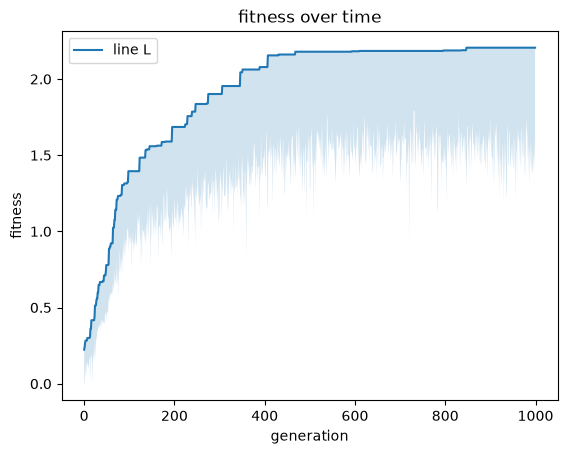

In [228]:
%pip install matplotlib
import matplotlib.pyplot as plt

x  = range(1000)
plt.plot(x, max_fitnesses, label="line L")
plt.fill_between(x, min_fitnesses, max_fitnesses, alpha=0.2)
plt.plot()

plt.xlabel("generation")
plt.ylabel("fitness")
plt.title("fitness over time")
plt.legend()
plt.show()

In [229]:
for i in range (5):
    pprint.PrettyPrinter(indent=2, depth=3).pprint(population[i])


{ 'fitness': 2.20585945776415,
  'ingredients': [ { 'amount': 1,
                     'cons': 'SOLID',
                     'flavour': 'spice',
                     'is_indonesian': True,
                     'name': 'ground cloves',
                     'source': 'Maple-Glazed Apple Cookies',
                     'type': 'spices',
                     'unit': 'g'},
                   { 'amount': 1,
                     'cons': 'SOLID',
                     'flavour': 'none',
                     'is_indonesian': False,
                     'name': 'arrowroot flour',
                     'source': 'Gluten Free Oatmeal Raisin Cookies',
                     'type': 'starches',
                     'unit': 'g'},
                   { 'amount': 1,
                     'cons': 'SOLID',
                     'flavour': 'salt',
                     'is_indonesian': False,
                     'name': 'sea salt',
                     'source': 'Gluten Free Oatmeal Raisin Cookies',
              